---
title: "Hufton, Mayorga and Sircar (1999): the equilibrium limit of sorption-enhanced steam reforming"
description: "The paper's case for sorption-enhanced reforming rests on a batch equilibrium of steam reforming and the water-gas shift with a fraction f of the CO2 removed; this page re-solves its Eqs. 3 to 10 and tests the printed numbers and the sentences built on them."
categories: [sec:I, struct:S10, tier:T1, data:tier6, phase:gas-solid]
date: 2026-11-27
---

# Hufton, Mayorga and Sircar (1999): the equilibrium limit of sorption-enhanced reforming

**Catalog ID:** `I1.9` · **Structures:** `S10` (algebraic equilibrium system) · **Tier:** T1

Sorption-enhanced reaction (SERP) packs a steam-reforming catalyst with a CO2 sorbent, so
that removing CO2 drives methane conversion and the shift towards hydrogen at a much lower
temperature than a conventional reformer. Hufton, Mayorga and Sircar make the case for it
with one calculation: the batch equilibrium of steam reforming (SMR) and the water-gas
shift (WGS) when a fraction $f$ of the CO2 made is removed (Eqs. 3 to 10, p. 250). Its
results are printed as numbers (p. 251 and the two SMR rows of Table 1, p. 255) and as
Fig. 3. The rest of the paper is a sorbent and a bench-scale experiment, for which it
prints no column model. This page re-solves the printed equilibrium and asks whether the
printed numbers, and the sentences built on them, follow from it.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.10"  # replaced by the release tag at publication
PYMRM = ">=3.4.1,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "I1.9-sorption-enhanced-reforming"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Nothing beyond pymrm and the Colab defaults.
import contextlib
import importlib.util
import io
import re
import time
from dataclasses import dataclass, field, replace

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import check_jacobian
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (Branch, Case, half_unit_interval, langmuir_theta, psig_to_atm,
                   serp_closure, solve_extents, solve_species, unique_root, with_om,
                   extent_residual)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
T_START = time.time()


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))


def page_module(page):
    """Import another page's model.py: from the checkout, else from GitHub at GALLERY_REF."""
    src = next((p / "pages" / page / "model.py" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "pages" / page / "model.py").is_file()), None)
    if src is None:
        src = _shared / f"{page}-model.py"
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/computational-chemical-engineering/"
            f"pymrm-gallery/{GALLERY_REF}/pages/{page}/model.py", src)
    name = page.split("-")[0].replace(".", "_") + "_model"
    spec = importlib.util.spec_from_file_location(name, src)
    mod = importlib.util.module_from_spec(spec)
    sys.modules[name] = mod            # dataclasses look their module up while defining
    spec.loader.exec_module(mod)
    return mod

## Background

Steam reforming, CH4 + H2O ⇌ CO + 3H2 (reaction 1, p. 248), is strongly endothermic, so a
conventional reformer runs hot to convert methane; the shift, CO + H2O ⇌ CO2 + H2
(reaction 2), then leaves CO and CO2 in the product. Removing CO2 from the reaction zone
moves both equilibria to the right at a moderate temperature (Le Chatelier). SERP does
this with a hydrotalcite-based chemisorbent mixed with the catalyst, regenerated by
pressure swing.

The paper's argument has three parts: the batch equilibrium with a fraction $f$ of the
CO2 removed (Eqs. 3 to 10) and its Fig. 3 at 450 °C; the sorbent (isotherm, breakthrough,
desorption at 400 °C, dry); and one bench-scale SERP run at 450 °C and 55 psig, compared
with the equilibrium of a conventional reformer in Table 1. Only the first part is a
model with printed equations. The paper prints no kinetics, no sorbent capacity at
450 °C (Figs. 4 and 5 are at 400 °C), no void fraction and no mass-transfer coefficient;
the desorption model behind Fig. 8 (p. 253) is cited, not printed. So the SERP column
cannot be re-solved from it; that is out of scope here, not judged. The question this
page answers: **do the printed equilibrium numbers, and the sentences built on them,
follow from the printed equations?** The answer is in the closing cell of the Results.

The catalogue line for `I1.9` lists structures S4 + S12 (a transient column with a
moving front). The paper carries no such model; what it does carry is an algebraic
equilibrium system, `S10`, and the page is filed as that.

## The published model

Per mole of feed (H2O/CH4 = $\alpha$), $\beta$ moles of CO are made by SMR and $\delta$
moles shifted by WGS; a fraction $f$ of the CO2 made is held by the sorbent. Eq. (7),
p. 250, gives the gas mole fractions

$$y_{H_2} = \frac{3\beta+\delta}{1+2\beta-f\delta},\quad
y_{CH_4} = \frac{1-\beta(1+\alpha)}{(1+\alpha)(1+2\beta-f\delta)},\quad
y_{H_2O} = \frac{\alpha-(\beta+\delta)(1+\alpha)}{(1+\alpha)(1+2\beta-f\delta)},$$
$$y_{CO} = \frac{\beta-\delta}{1+2\beta-f\delta},\quad
y_{CO_2} = \frac{(1-f)\delta}{1+2\beta-f\delta},$$

and the equilibria (3) and (4), $K_{SMR}(T) = P^2 y_{H_2}^3 y_{CO}/(y_{CH_4} y_{H_2O})$
(atm², $P$ absolute in atm) and $K_{WGS}(T) = y_{CO_2} y_{H_2}/(y_{CO} y_{H_2O})$, become
Eqs. (8) and (9) in $\beta$ and $\delta$:

$$K_{SMR} = \frac{P^2(\beta-\delta)(3\beta+\delta)^3(1+\alpha)^2}
{[1+2\beta-f\delta]^2[1-\beta(1+\alpha)][\alpha-(1+\alpha)(\beta+\delta)]},\qquad
K_{WGS} = \frac{(1-f)\delta(3\beta+\delta)(1+\alpha)}{(\beta-\delta)[\alpha-(\beta+\delta)(1+\alpha)]}.$$

Eq. (10), $\chi = (3\beta+\delta)(1+\alpha)$, is the moles of H2 formed per mole of CH4
fed, and the text names "the CH4 to H2 conversion (= χ/4)" (p. 251). The carbon-based
conversion is $X_{CH_4} = \beta(1+\alpha)$; the two coincide only when $\delta = \beta$.
Eqs. (5) and (6) are rearrangements used for a qualitative remark.

| symbol | meaning | code |
|---|---|---|
| $\alpha$ | feed H2O/CH4 | `Case.alpha` |
| $1-f$ | fraction of the CO2 made left in the gas | `Case.om` |
| $\beta$, $\delta$ | SMR and WGS extents per mole feed | `State.beta`, `State.delta` |
| $y_i$ (Eq. 7) | wet mole fractions | `State.y`; dry: `State.ydry` |
| $\chi/4$ (Eq. 10) | the paper's "CH4 to H2 conversion" | `State.chi4` |
| $X_{CH_4}$ | carbon-based CH4 conversion | `State.X` |
| Eqs. (8), (9) | residuals in $\ln$ of both sides | `extent_residual` |

Reading notes, each checked against the page image: (M1) Eq. (6) as printed has
$[y_{H_2}]^{0.5}$ in the denominator; eliminating $y_{H_2O}$ between (3) and (4) gives
$[y_{H_2O}]^{0.5}$ there. The Validation measures the printed form's error. Eq. (6) feeds
only the remark "the gas-phase CO mole fraction decreases as the corresponding CO2 mole
fraction decreases" (p. 250), which holds in both forms. (M6) "Y_CH4" with a capital Y in
Eqs. (5) and (6) is $y_{CH_4}$. Fig. 3's abscissa is "(1-f)x100 (%)" on a log axis; the
text says "as a function of ln (1 − f)" (p. 251), the same thing.

## Parameters and assumptions

| quantity | value | source |
|---|---|---|
| $\alpha$ | printed | p. 251, Table 1 |
| $T$, $P$ of Fig. 3 and the p. 251 numbers | 450 °C, 50 psig | p. 251 |
| $T$, $P$ of Table 1's SMR rows | 450 and 645 °C, 55 psig | p. 255 |
| psig to kPa | "kPa = (psig+ 14.7) × 6.89" | Table 1 footnote, p. 255 |
| $K_{SMR}(T)$, $K_{WGS}(T)$ | the correlations of page `C2.1` | not printed in this paper |

**The equilibrium constants are not printed.** The paper cites them to Twigg (1989) and
shows them only as curves on the logarithmic K axis of Fig. 2 (1.E-11 to 1.E+07), which
cannot pin K at the per-cent level. The page uses the correlations of gallery page
`C2.1` (attributed there to the same handbook), loaded from that page's `model.py`:
$K_{SMR} = \exp(-26830/T + 30.114)$ bar², converted here to atm², and
$K_{WGS} = \exp(4400/T - 4.036)$. Which K the authors used is unknown, so every verdict
below is also evaluated with each K multiplied independently by $1 \pm e$ (the four
corners and the centre). **The band $e$ is an assumption**, set in the next cell: twice
the 5 % shift `C2.1` applies to the same constants as its own sensitivity. It is chosen,
not measured: the page cannot compare the correlation with the tables the authors read.
A verdict that changes inside the band is reported as undecided.

Assumptions of the paper's model, kept: ideal gas, constant $T$ and $P$, a batch with no
carbon formation, and the sorbent as a sink for a fixed fraction $f$ of the CO2 made
(no isotherm). 50 psig is converted with the paper's own footnote.

In [3]:
BAND = 0.10                  # relative K band e (assumption; see the text above)
C21 = "C2.1-xu-froment-smr"  # the page whose K(T) correlations are used
BAR_PER_ATM = 1.01325        # bar in one standard atmosphere (definition)
c21 = page_module(C21)
KIN = c21.XuFroment.from_table(load_data("xu-froment-1989-parameters.csv", page=C21))
print("K(T) from page C2.1, XuFroment.eq =", KIN.eq, "(K_SMR in bar^2, K_WGS dimensionless)")

K(T) from page C2.1, XuFroment.eq = (26830.0, 30.114, 4400.0, -4.036) (K_SMR in bar^2, K_WGS dimensionless)


## The data

The printed numbers are in `data/hufton-1999-printed-numbers.csv`, read as strings so
that each is compared in half-units of its last printed digit. They are computed
results (p. 251, Table 1's SMR rows) and the reported numbers of one experiment (Table 1's
SERP row, p. 254 to 255); nothing on this page is a measurement fitted or tested by the
model. `data/check_values.csv` holds independent values from a second route (a scipy
script with two formulations, no pymrm and no page code).

From page `C2.1` only the equilibrium correlation is used (its parameter table is loaded
because its model class is built from it; no kinetic constant enters here). `C2.1`'s
findings about it: it is "not from this paper" (Xu and Froment), its van 't Hoff slopes
are tested there against Xu and Froment's Table 7 enthalpies, and "the long-space-time
residual is the size of a 5 % change in them". This page uses the correlation over
450 to 900 °C, outside the 500 to 575 °C at which `C2.1` tests it, and takes the 5 % as
the scale of its K band.

In [4]:
PN = load_data("hufton-1999-printed-numbers.csv", page=PAGE, dtype=str)
print(cite_data(load_meta("hufton-1999-printed-numbers.csv", page=PAGE)))
print(f"{len(PN)} printed entries, pages {', '.join(sorted(set(PN['page'])))}")
for item in ("p251_f0_conv_pct", "p251_f0_H2_pct", "t1_450_H2_pct", "t1_645_H2_pct",
             "t1_645_conv_pct", "p253_langmuir_b_per_atm"):
    r = PN.set_index("item").loc[item]
    print(f"  {item:26s} {r['printed']:>6s} {r['unit']:7s} p. {r['page']}  {r['meaning']}")

Hufton, J. R.; Mayorga, S.; Sircar, S. (1999) — AIChE Journal 45, 248-256 — doi:10.1002/aic.690450205 — table
46 printed entries, pages 251, 253, 254, 255
  p251_f0_conv_pct             28.0 %       p. 251  CH4 to H2 conversion with no CO2 removed, "only 28.0%"
  p251_f0_H2_pct               52.8 %       p. 251  dry H2 mole fraction with no CO2 removed
  t1_450_H2_pct                  53 %       p. 255  Table 1, SMR at 450 C and 55 psig: dry H2
  t1_645_H2_pct                75.5 %       p. 255  Table 1, SMR at 645 C and 55 psig: dry H2
  t1_645_conv_pct                82 %       p. 255  Table 1, SMR at 645 C: CH4 conversion
  p253_langmuir_b_per_atm      39.9 atm^-1  p. 253  Langmuir b of the Fig. 6 fit, "[b = 39.9 atm^-1]" (400 C, dry CO2/N2)


## PyMRM implementation

The model has two unknowns per condition. Route A solves Eqs. (8) and (9) with
`pymrm.newton` in $u = (\ln s, \ln t)$, where $s = 1-\beta(1+\alpha)$ is the unconverted
CH4 fraction and $t = (\beta-\delta)/\beta$ the unshifted CO fraction. Both go to zero as
$f \to 1$; in logs the iteration stays in the feasible set, and the two factors that
vanish are taken from the unknowns, not by subtraction, so $1-f$ down to 1e-6 resolves
without cancellation. The residuals are $\ln K$ minus the log of each right-hand side,
with the analytic Jacobian (checked by `pymrm.checks.check_jacobian`). A state far from
$f = 0$ is reached by continuation in $\ln(1-f)$ from $f = 0$, and neighbouring states
are warm-started (`model.Branch`). Every threshold in $1-f$ or $T$ is a root found by
`pymrm.checks.find_roots` on the physical range, which raises unless it finds exactly one
root (`model.unique_root`).

Route B, the validation route, solves five gas amounts from the C, H and O balances
(sorbed CO2 included) and Eqs. (3) and (4), also by `pymrm.newton`, from a flat start.

There is no grid and no time step, so no refinement study applies; the only numerical
approximations are the Newton and root tolerances, measured in the Validation.

The study below computes every reported number from a configuration `Cfg`; the break
table re-runs it with one defect injected through `Cfg`.

In [5]:
@dataclass(frozen=True)
class Cfg:
    """Everything a defect can change: the printed strings, the K functions, readings."""
    pn: dict = field(default_factory=lambda: dict(zip(PN["item"], PN["printed"])))
    band: float = BAND           # relative K band
    band_narrow: float = 0.05    # the narrower K band of the Table 1 count
    wgs_inverted: bool = False   # K_WGS replaced by 1/K_WGS (break row)
    p_unit: str = "psig"         # "psig_as_atm": the gauge number passed as atm (break row)
    t1_conv: str = "X"           # which conversion Table 1 is compared with ("X" or "chi4")
    h2_basis: str = "dry"        # basis of the 95 % H2 test
    o_sorbed: float = 2.0        # oxygens per sorbed CO2 in route B
    jac_slip: float = 0.0        # wrong term added to the route A Jacobian
    tol_loose: float = 1e-8      # loose rung of the tolerance ladder (step and backward error)

    def num(self, item):
        return float(self.pn[item])

    def P(self, item):
        """Pressure (atm) of a printed psig entry."""
        g = self.num(item)
        return g if self.p_unit == "psig_as_atm" else psig_to_atm(
            g, self.num("t1_kpa_per_psi"), self.num("t1_psi_offset"))

    def kfun(self, fs=1.0, fw=1.0):
        """K(T) of page C2.1 in atm^2, scaled by (fs, fw)."""
        def k(T):
            k1, k2, _ = KIN.equilibrium(T)
            kw = 1.0 / k2 if self.wgs_inverted else k2
            return fs * k1 / BAR_PER_ATM ** 2, fw * kw
        return k

    def ksets(self):
        """The centre and the four corners of the K band."""
        e = self.band
        return [(1.0, 1.0)] + [(1 + a * e, 1 + b * e) for a in (-1, 1) for b in (-1, 1)]

    def case(self, T_item=None, P_item="p251_P_psig", om=1.0, T_C=None, k=(1.0, 1.0)):
        T = self.num(T_item) if T_C is None else T_C
        return Case(T, self.P(P_item), om, self.kfun(*k), self.num("alpha"))


C0 = Cfg()


def cells(st):
    """Dry fractions and conversions in percent, keyed as the printed items."""
    d = st.ydry
    return {"H2": 100 * d["H2"], "CH4": 100 * d["CH4"], "CO2": 100 * d["CO2"],
            "CO": 100 * d["CO"], "COx": 100 * (d["CO"] + d["CO2"]),
            "X": 100 * st.X, "chi4": 100 * st.chi4}


def overlap_margin(printed, lo, hi):
    """Signed overlap of the printed string's rounding interval with [lo, hi] (points)."""
    a, b = half_unit_interval(printed)
    return min(b - lo, hi - a)


def round_margin(printed, x):
    """Signed distance of x inside the printed string's rounding interval (points)."""
    a, b = half_unit_interval(printed)
    return min(x - a, b - x)

R1, the $f = 0$ state at 450 °C and 50 psig, against "28.0%" and the four dry fractions
of p. 251; R5, the 645 °C row of Table 1. Each printed cell is consistent when its
rounding interval overlaps the range the K band gives.

In [6]:
R1_CELLS = {"chi4": "p251_f0_conv_pct", "H2": "p251_f0_H2_pct", "CH4": "p251_f0_CH4_pct",
            "CO2": "p251_f0_CO2_pct", "CO": "p251_f0_CO_pct"}


def band_cells(c, case_kw):
    """Cells at the centre and their (min, max) over the K band."""
    vals = [cells(solve_extents(c.case(k=k, **case_kw))) for k in c.ksets()]
    return vals[0], {n: (min(v[n] for v in vals), max(v[n] for v in vals)) for n in vals[0]}


def consistency(c, M, tag, nominal, band, cellmap):
    """Count printed cells inside the band (with margin) and cells that round (centre K)."""
    inside, rounds = [], []
    for key, item in cellmap.items():
        p = c.pn[item]
        M[f"{tag}_{key}"] = nominal[key]
        M[f"{tag}_gap_{key}"] = nominal[key] - float(p)
        inside.append(overlap_margin(p, *band[key]))
        rounds.append(round_margin(p, nominal[key]))
    M[f"{tag}_n_consistent"] = int(sum(m >= 0 for m in inside))
    M[f"{tag}_n_consistent__margin"] = float(min(abs(m) for m in inside))
    M[f"{tag}_n_round"] = int(sum(m >= 0 for m in rounds))
    M[f"{tag}_n_round__margin"] = float(min(abs(m) for m in rounds))


def part_r1(c, M):
    nom, band = band_cells(c, dict(T_item="p251_T_C", P_item="p251_P_psig"))
    consistency(c, M, "r1", nom, band, R1_CELLS)
    M["r1_X"] = nom["X"]


def part_r5(c, M):
    key = "X" if c.t1_conv == "X" else "chi4"
    nom, band = band_cells(c, dict(T_item="t1_645_T_C", P_item="t1_645_P_psig"))
    consistency(c, M, "r5", nom, band, {"H2": "t1_645_H2_pct", "CH4": "t1_645_CH4_pct",
                                        "COx": "t1_645_COx_pct", key: "t1_645_conv_pct"})
    # The same count at the narrower band, in both K (a separate call, so its tag is its own).
    cn = replace(c, band=c.band_narrow)
    nom, band = band_cells(cn, dict(T_item="t1_645_T_C", P_item="t1_645_P_psig"))
    Mn = {}
    consistency(cn, Mn, "n", nom, band, {"H2": "t1_645_H2_pct", "CH4": "t1_645_CH4_pct",
                                         "COx": "t1_645_COx_pct", key: "t1_645_conv_pct"})
    M["r5_n_consistent_band5"] = Mn["n_n_consistent"]
    M["r5_n_consistent_band5__margin"] = Mn["n_n_consistent__margin"]

R2, the sentence on Fig. 3 (p. 251): the state at the printed 99.9 % removal and the
thresholds in $1-f$ at which the dry H2 reaches 95 %, the dry carbon oxides fall to
100 ppm and $\chi/4$ reaches 80 %, each a root in $\ln(1-f)$ on [1e-6, 0.5].

In [7]:
def r2_quantities(st, c):
    """Dry (or, as a break row, wet) H2 %, carbon oxides ppm and chi/4 %."""
    h2 = st.ydry["H2"] if c.h2_basis == "dry" else st.y["H2"]
    return 100 * h2, st.cox_ppm, 100 * st.chi4


def om_threshold(c, k, which, level):
    """1 - f at which quantity ``which`` (0 H2, 1 COx, 2 chi/4) equals ``level``."""
    br = Branch()
    base = c.case(T_item="p251_T_C", P_item="p251_P_psig", k=k)
    f = lambda lo: r2_quantities(br.solve(with_om(base, np.exp(lo))), c)[which] - level
    return float(np.exp(unique_root(f, np.log(1e-6), np.log(0.5), log=False, xtol=1e-11)))


def part_r2(c, M):
    om = 1 - c.num("p251_claim_removed_pct") / 100
    levels = (c.num("p251_claim_H2_pct"), c.num("p251_claim_COx_ppm"), c.num("p251_claim_conv_pct"))
    q = np.array([r2_quantities(solve_extents(c.case("p251_T_C", om=om, k=k)), c)
                  for k in c.ksets()])
    for i, n in enumerate(("H2", "COx_ppm", "chi4")):
        M[f"r2_999_{n}"] = q[0, i]
        try:                      # a level the range cannot reach records nan, not a crash
            M[f"r2_om_star_{n}"] = om_threshold(c, (1.0, 1.0), i, levels[i])
        except ValueError:
            M[f"r2_om_star_{n}"] = float("nan")
    stars = [om_threshold(c, k, 1, levels[1]) for k in c.ksets()[1:]]
    M["r2_om_star_COx_ppm_band_max"] = max(stars)
    M["r2_cox_holds"] = bool(q[:, 1].max() < levels[1])
    M["r2_cox_holds__margin"] = float(abs(q[:, 1].min() / levels[1] - 1))
    M["r2_h2_holds"] = bool(q[:, 0].min() > levels[0])
    M["r2_h2_holds__margin"] = float(abs(levels[0] - q[:, 0].max()))
    lo, hi = q[:, 2].min(), q[:, 2].max()
    M["r2_conv_verdict"] = "holds" if lo > levels[2] else ("fails" if hi < levels[2] else "undecided")
    M["r2_conv_verdict__margin"] = float(min(abs(levels[2] - lo), abs(hi - levels[2])))
    M["_r2_band"] = q

R3, which conversion Table 1 carries: the printed composition of the 645 °C row gives
both conversions by arithmetic alone, and the re-solve gives the temperature at which
each reaches the printed 82, as a root in $T$ on [500, 900] °C at 55 psig. With the
printed 82's rounding interval and the K band, each definition gives a temperature
interval; Table 1's 645 °C is tested against both.

In [8]:
def t_root(c, k, which, level):
    """Temperature (degC) at which conversion ``which`` reaches ``level`` (fraction)."""
    br = Branch()
    f = lambda T: getattr(br.solve(c.case(P_item="t1_645_P_psig", T_C=T, k=k)), which) - level
    return unique_root(f, 500.0, 900.0, n_scan=41, xtol=1e-9)


def part_r3(c, M):
    p = {k_: c.num(f"t1_645_{k_}_pct") for k_ in ("H2", "CH4", "COx")}
    M["r3_printed_Xcarbon"] = p["COx"] / (p["CH4"] + p["COx"])
    M["r3_printed_chi4"] = p["H2"] / (4 * (p["CH4"] + p["COx"]))
    conv = c.pn["t1_645_conv_pct"]
    T645 = c.num("t1_645_T_C")
    lo, hi = (v / 100 for v in half_unit_interval(conv))
    for which in ("X", "chi4"):
        M[f"r3_Tstar_{which}"] = t_root(c, (1.0, 1.0), which, float(conv) / 100)
        ends = [t_root(c, k, which, lev) for k in c.ksets()[1:] for lev in (lo, hi)]
        M[f"_r3_{which}_interval"] = (min(ends), max(ends))
    key = c.t1_conv
    a, b = M[f"_r3_{key}_interval"]
    M["r3_645_in_table1_interval"] = bool(a <= T645 <= b)
    M["r3_645_in_table1_interval__margin"] = float(min(abs(T645 - a), abs(b - T645)))
    other = "chi4" if key == "X" else "X"
    a, b = M[f"_r3_{other}_interval"]
    M["r3_645_in_other_interval"] = bool(a <= T645 <= b)
    M["r3_645_in_other_interval__margin"] = float(min(abs(T645 - a), abs(b - T645)))

R4, the pressure of Table 1's 450 °C row. The K band alone is too wide to tell 50 from 55
psig by a direct re-solve (measured below). The paper's own 50 psig numbers of p. 251
carry the authors' K. So each printed p. 251 value is moved by the model's change from 50
to 55 psig (the same K at both pressures) and compared with Table 1's integer. A cell
counts when the moved value rounds to the printed integer with room for the p. 251
rounding and the spread of the pressure shift over the K band.

In [9]:
R4_CELLS = {"H2": ("t1_450_H2_pct", ("p251_f0_H2_pct",)),
            "CH4": ("t1_450_CH4_pct", ("p251_f0_CH4_pct",)),
            "COx": ("t1_450_COx_pct", ("p251_f0_CO2_pct", "p251_f0_CO_pct")),
            "conv": ("t1_450_conv_pct", ("p251_f0_conv_pct",))}


def part_r4(c, M):
    key = "X" if c.t1_conv == "X" else "chi4"
    shifts, direct = [], []
    for k in c.ksets():
        lo = cells(solve_extents(c.case("p251_T_C", "p251_P_psig", k=k)))
        hi = cells(solve_extents(c.case("p251_T_C", "t1_450_P_psig", k=k)))
        shifts.append({n: hi[key if n == "conv" else n] - lo[key if n == "conv" else n]
                       for n in R4_CELLS})
        direct.append(sum(round_margin(c.pn[t], hi[key if n == "conv" else n]) >= 0
                          for n, (t, _) in R4_CELLS.items()))
    for dp, tag in ((False, "p50"), (True, "p55")):
        n_ok, margins = 0, []
        for n, (t, src) in R4_CELLS.items():
            anchor = sum(float(c.pn[s]) for s in src)
            half = sum(np.diff(half_unit_interval(c.pn[s]))[0] / 2 for s in src)
            sh = [s_[n] for s_ in shifts] if dp else [0.0]
            x = anchor + sh[0]
            allow = half + (max(sh) - min(sh))
            m = round_margin(c.pn[t], x)
            n_ok += m >= 0
            margins.append(abs(m) - allow)
            if dp:
                M[f"r4_shift_{n}"] = sh[0]
        M[f"r4_n_{tag}"] = int(n_ok)
        M[f"r4_n_{tag}__margin"] = float(min(margins))
    M["r4_direct_n55_centre"] = int(direct[0])
    M["r4_direct_n55_band_max"] = int(max(direct))

R6 and R7 are closed forms of printed numbers: the H2 purity the SERP run's printed
conversion allows if all unconverted CH4 and no carbon oxide reach the product (p. 255),
and the Langmuir coverages behind the sentence on Figs. 4 and 5 (p. 253).

In [10]:
def part_r6_r7(c, M):
    X = c.num("p255_conv_pct") / 100
    M["r6_yH2_closure"] = serp_closure(X)
    M["r6_X_for_purity"] = 1 / (4 / (c.num("p255_purity_pct") / 100) - 3)
    M["r6_yH2_closure_press"] = serp_closure(X, c.num("p255_net_H2_molkg"),
                                             c.num("p254_press_H2_molkg"))
    M["r6_gap_pts"] = c.num("p255_purity_pct") - 100 * M["r6_yH2_closure"]
    M["r6_gap_press_pts"] = c.num("p255_purity_pct") - 100 * M["r6_yH2_closure_press"]
    b = c.num("p253_langmuir_b_per_atm")
    M["r7_theta_lo"] = langmuir_theta(c.num("p253_pCO2_lo_atm"), b)
    M["r7_theta_hi"] = langmuir_theta(c.num("p253_pCO2_hi_atm"), b)
    M["r7_theta_ratio"] = M["r7_theta_lo"] / M["r7_theta_hi"]
    M["r7_theta_y0"] = langmuir_theta(c.num("p253_y0"), b)

Validation parts: route A against route B on sweeps in $1-f$ and $T$ (with the element
balances and the Eq. (5) and (6) identities at every state), the limits, the Jacobian and
the Newton tolerance ladder.

In [11]:
OM_SWEEP = np.geomspace(1e-6, 1.0, 25)
T_SWEEP = np.linspace(450.0, 900.0, 10)


def sweep_states(c):
    base = c.case("p251_T_C", "p251_P_psig")
    br = Branch()
    out = [br.solve(with_om(base, om)) for om in OM_SWEEP[::-1]]
    for om in (1.0, 1e-3):
        br = Branch()
        out += [br.solve(replace(base, T_C=T, om=om)) for T in T_SWEEP]
    return out


def part_v1_v3(c, M):
    gaps, bal, e5, e6 = [], [], [], []
    for st in sweep_states(c):
        yb = solve_species(st.case, [0.1] * 5, o_sorbed=c.o_sorbed)
        gaps.append(max(abs(yb[k] / v - 1) for k, v in st.y.items()))
        bal.append(np.max(np.abs(st.element_gaps())))
        g5, g6, _ = st.eq5_eq6()
        e5.append(abs(g5))
        e6.append(abs(g6))
    M["v1_route_gap"] = max(gaps)
    M["v1_element_balance"] = max(bal)
    M["v3_eq5_gap"] = max(e5)
    M["v3_eq6_corrected_gap"] = max(e6)
    st = solve_extents(c.case("p251_T_C", "p251_P_psig"))
    ratio = st.eq5_eq6()[2]
    M["v3_eq6_printed_ratio"] = ratio
    M["v3_eq6_ratio_vs_sqrt"] = abs(ratio / np.sqrt(st.y["H2O"] / st.y["H2"]) - 1)


def part_v2(c, M):
    base = c.case("p251_T_C", "p251_P_psig")
    br = Branch()
    for om in (1e-2, 1e-4, 1e-6):
        a, b = br.solve(with_om(base, om)), br.solve(with_om(base, om * 1.01))
        M[f"v2_slope_{om:.0e}"] = (np.log(b.ydry["CH4"] / a.ydry["CH4"]) / np.log(1.01))
        M[f"v2_chi4_minus_X_{om:.0e}"] = 100 * (a.chi4 - a.X)
    M["v2_X_P_low"] = solve_extents(replace(base, P_atm=1e-4)).X


def part_v4(c, M):
    st = solve_extents(c.case("p251_T_C", "p251_P_psig", om=1e-3))
    off = st.u + np.array([0.3, -0.4])        # away from the root, every term active
    M["v4_jacobian"] = check_jacobian(lambda u: extent_residual(u, st.case, c.jac_slip),
                                      off)["max_rel_error"]
    worst = 0.0
    for om in (1.0, 1e-3, 1e-6):
        case = with_om(st.case, om)
        a = solve_extents(case, tol=c.tol_loose, backward_tol=c.tol_loose)
        b = solve_extents(case, tol=1e-12, backward_tol=1e-12)
        worst = max(worst, abs(a.X / b.X - 1), abs(a.ydry["CH4"] / b.ydry["CH4"] - 1))
    M["v4_tol_effect"] = worst

In [12]:
PARTS = {"r1": part_r1, "r2": part_r2, "r3": part_r3, "r4": part_r4, "r5": part_r5,
         "r67": part_r6_r7, "v13": part_v1_v3, "v2": part_v2, "v4": part_v4}


def study(c, parts=tuple(PARTS)):
    """Every reported number of the page, for configuration ``c``."""
    M = {}
    for p in parts:
        PARTS[p](c, M)
    return M


M = study(C0)

In [13]:
# Check values from the second route (data/check_values.meta.yaml), before any claim.
P50 = C0.case("p251_T_C", "p251_P_psig")
st0 = solve_extents(P50)
st9 = solve_extents(with_om(P50, 1e-3))
st645 = solve_extents(C0.case("t1_645_T_C", "t1_645_P_psig"))
st450 = solve_extents(C0.case("p251_T_C", "t1_450_P_psig"))
K450 = P50.K()
CV = {"P_atm_50psig": P50.P_atm, "K_SMR_atm2_450C": K450[0], "K_WGS_450C": K450[1],
      "f0_XCH4": st0.X, "f0_chi4": st0.chi4, "f0_beta": st0.beta, "f0_delta": st0.delta,
      "eq6_printed_over_yCO": M["v3_eq6_printed_ratio"],
      "f999_chi4": st9.chi4, "f999_ydry_H2": st9.ydry["H2"], "f999_COx_dry_ppm": st9.cox_ppm,
      "om_star_H2dry95": M["r2_om_star_H2"], "om_star_COx100ppm": M["r2_om_star_COx_ppm"],
      "om_star_chi4_80": M["r2_om_star_chi4"],
      "T645_p55_XCH4": st645.X, "T645_p55_chi4": st645.chi4,
      "T645_p55_ydry_COx": st645.ydry["CO"] + st645.ydry["CO2"],
      "T450_p55_XCH4": st450.X, "T450_p55_ydry_COx": st450.ydry["CO"] + st450.ydry["CO2"],
      "Tstar_C_XCH4_82_p55": M["r3_Tstar_X"], "Tstar_C_chi4_82_p55": M["r3_Tstar_chi4"],
      "printed_t1_645_Xcarbon": M["r3_printed_Xcarbon"], "printed_t1_645_chi4": M["r3_printed_chi4"],
      "theta_p0.3": M["r7_theta_lo"], "theta_p0.7": M["r7_theta_hi"],
      "theta_ratio_0.3_over_0.7": M["r7_theta_ratio"], "theta_p0.657": M["r7_theta_y0"],
      "serp_yH2_closure_X082": M["r6_yH2_closure"], "serp_X_for_yH2_096": M["r6_X_for_purity"],
      "serp_yH2_closure_with_press_H2": M["r6_yH2_closure_press"]}
for sp in ("H2", "CH4", "CO", "CO2"):
    CV[f"f0_ydry_{sp}"] = st0.ydry[sp]
for sp in ("H2", "CH4"):
    CV[f"T645_p55_ydry_{sp}"] = st645.ydry[sp]
    CV[f"T450_p55_ydry_{sp}"] = st450.ydry[sp]
pn = C0.pn
CV["printed_t1_450_Xcarbon"] = float(pn["t1_450_COx_pct"]) / (float(pn["t1_450_CH4_pct"]) + float(pn["t1_450_COx_pct"]))
CV["printed_t1_450_chi4"] = float(pn["t1_450_H2_pct"]) / (4 * (float(pn["t1_450_CH4_pct"]) + float(pn["t1_450_COx_pct"])))
_cox = float(pn["p251_f0_CO2_pct"]) + float(pn["p251_f0_CO_pct"])
CV["printed_p251_f0_Xcarbon"] = _cox / (float(pn["p251_f0_CH4_pct"]) + _cox)
CV["printed_p251_f0_chi4"] = float(pn["p251_f0_H2_pct"]) / (4 * (float(pn["p251_f0_CH4_pct"]) + _cox))
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(CV, page=PAGE)
say("Check values: <<n:d>> of <<t:d>> rows agree, each inside its own tolerance; worst "
    "relative deviation <<w:.1e>>.", n=len(DEV), t=len(CV), w=max(abs(v) for v in DEV.values()))

Check values: 42 of 42 rows agree, each inside its own tolerance; worst relative deviation 2.7e-12.

## Results

### Fig. 3 re-solved

The equilibrium against the fraction of CO2 left in the gas, at 450 °C and 50 psig, as
in the paper's Fig. 3 (no figure is digitised here; the paper's curves are not
reproduced). The shaded range is the K band; the dashed lines are the levels of the
sentence on p. 251.

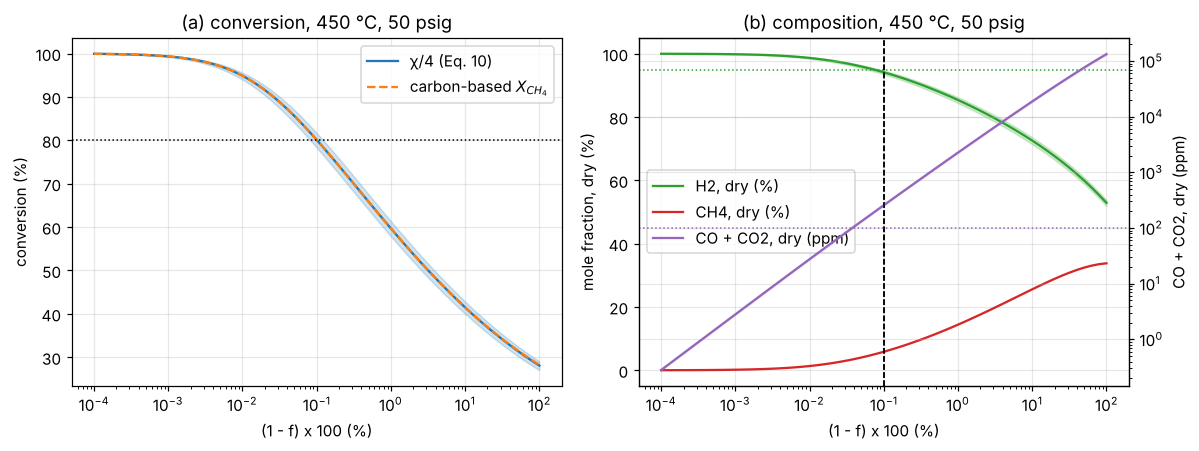

In [14]:
OM_FIG = np.geomspace(1e-6, 1.0, 61)


def fig3_curves(c, k):
    br = Branch()
    base = c.case("p251_T_C", "p251_P_psig", k=k)
    sts = [br.solve(with_om(base, om)) for om in OM_FIG[::-1]][::-1]
    return np.array([[100 * s.chi4, 100 * s.X, 100 * s.ydry["H2"], s.cox_ppm,
                      100 * s.ydry["CH4"]] for s in sts])


CURVES = [fig3_curves(C0, k) for k in C0.ksets()]
lo_c, hi_c = np.min(CURVES, axis=0), np.max(CURVES, axis=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
x = 100 * OM_FIG
ax[0].fill_between(x, lo_c[:, 0], hi_c[:, 0], color="C0", alpha=0.2)
ax[0].plot(x, CURVES[0][:, 0], "C0", label="χ/4 (Eq. 10)")
ax[0].plot(x, CURVES[0][:, 1], "C1--", label="carbon-based $X_{CH_4}$")
ax[0].axhline(C0.num("p251_claim_conv_pct"), color="k", ls=":", lw=1)
ax[0].set(xscale="log", xlabel="(1 - f) x 100 (%)", ylabel="conversion (%)",
          title="(a) conversion, 450 °C, 50 psig")
ax[0].legend()
ax[1].fill_between(x, lo_c[:, 2], hi_c[:, 2], color="C2", alpha=0.2)
ax[1].plot(x, CURVES[0][:, 2], "C2", label="H2, dry (%)")
ax[1].plot(x, CURVES[0][:, 4], "C3", label="CH4, dry (%)")
ax[1].axhline(C0.num("p251_claim_H2_pct"), color="C2", ls=":", lw=1)
axr = ax[1].twinx()
axr.fill_between(x, lo_c[:, 3], hi_c[:, 3], color="C4", alpha=0.2)
axr.plot(x, CURVES[0][:, 3], "C4", label="CO + CO2, dry (ppm)")
axr.axhline(C0.num("p251_claim_COx_ppm"), color="C4", ls=":", lw=1)
axr.set(yscale="log", ylabel="CO + CO2, dry (ppm)")
for a_ in (ax[1], axr):
    a_.axvline(100 - C0.num("p251_claim_removed_pct"), color="k", ls="--", lw=1)
ax[1].set(xscale="log", xlabel="(1 - f) x 100 (%)", ylabel="mole fraction, dry (%)",
          title="(b) composition, 450 °C, 50 psig")
h1, l1 = ax[1].get_legend_handles_labels()
h2, l2 = axr.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, loc="center left")
fig.tight_layout()
plt.show()

### R1: the state with no CO2 removed (p. 251)

In [15]:
say("At 450 °C and 50 psig with $f = 0$ the re-solve gives χ/4 = <<c:.2f>> % "
    "($X_{CH_4}$ <<x:.2f>> %) against the printed \"28.0%\", and dry H2, CH4, CO2 and CO of "
    "<<h:.2f>>, <<m:.2f>>, <<o2:.2f>> and <<o:.3f>> % against the printed 52.8, 33.8, 12.9 "
    "and 0.34 % (gaps <<gh:+.2f>>, <<gm:+.2f>>, <<go2:+.2f>> and <<go:+.3f>> points). With the "
    "assumed ±<<b:.0f>> % K band in both constants, <<n:d>> of <<t:d>> printed cells are consistent (smallest overlap <<mg:.3f>> "
    "points). Only <<nr:d>> of <<t:d>> round to the printed string at the centre K, which is "
    "what an unprinted K allows: the cells move by tenths of a point inside the band.",
    c=M["r1_chi4"], x=M["r1_X"], h=M["r1_H2"], m=M["r1_CH4"], o2=M["r1_CO2"], o=M["r1_CO"],
    gh=M["r1_gap_H2"], gm=M["r1_gap_CH4"], go2=M["r1_gap_CO2"], go=M["r1_gap_CO"],
    n=M["r1_n_consistent"], t=len(R1_CELLS), mg=M["r1_n_consistent__margin"],
    nr=M["r1_n_round"], b=100 * C0.band)

At 450 °C and 50 psig with $f = 0$ the re-solve gives χ/4 = 28.08 % ($X_{CH_4}$ 28.26 %) against the printed "28.0%", and dry H2, CH4, CO2 and CO of 52.90, 33.79, 12.97 and 0.345 % against the printed 52.8, 33.8, 12.9 and 0.34 % (gaps +0.10, -0.01, +0.07 and +0.005 points). With the assumed ±10 % K band in both constants, 5 of 5 printed cells are consistent (smallest overlap 0.032 points). Only 1 of 5 round to the printed string at the centre K, which is what an unprinted K allows: the cells move by tenths of a point inside the band.

### R2: "> 95%" H2 and "< 100 ppm" carbon oxides at 99.9 % removal (p. 251)

The sentence, copied from p. 251: "Figures 3a and 3b clearly demonstrate that (a) very
high conversion of CH4 to H2 (> 80%) by the SMR-WGS reactions can be achieved at a
moderate temperature of 450°C, and (b) a gas phase, which has a large H2 mole fraction
(> 95%) and which is essentially free of carbon oxides (< 100 ppm) on a dry basis, can be
produced when 99.9% or more of the CO2 produced by the reactions is removed by the
adsorbent."

In [16]:
q = M["_r2_band"]
say("At 99.9 % removal ($1-f$ = 1e-3) the re-solve gives dry H2 <<h:.2f>> % (K band "
    "<<hl:.2f>> to <<hh:.2f>> %), dry CO + CO2 <<p:.1f>> ppm (band <<pl:.1f>> to <<ph:.1f>>), "
    "and χ/4 <<c:.2f>> % (band <<cl:.2f>> to <<ch:.2f>> %). The thresholds, as roots in "
    "$1-f$: 95 % dry H2 at $1-f$ = <<oh:.3e>>, 100 ppm carbon oxides at <<oc:.3e>> (at most "
    "<<ocm:.3e>> in the band), and χ/4 = 80 % at <<ov:.3e>>.\n\n"
    "- Carbon oxides: the 100 ppm bound holds at 99.9 %: **<<v1>>**; the lowest value in the "
    "band is <<r:.2f>> times the bound.\n"
    "- Dry H2 above 95 % at 99.9 %: **<<v2>>**; the band's highest value is <<hm:.2f>> points "
    "short.\n"
    "- χ/4 above 80 % at 99.9 %: **<<v3>>**; the band straddles 80 % (<<vm:.2f>> points to "
    "its nearer edge). Clause (a), \"> 80%\" at 450 °C, has no removal condition and holds: "
    "χ/4 reaches 80 % at $1-f$ = <<ov:.3e>>; the \"when\" clause governs (b) only.",
    h=M["r2_999_H2"], hl=q[:, 0].min(), hh=q[:, 0].max(), p=M["r2_999_COx_ppm"],
    pl=q[:, 1].min(), ph=q[:, 1].max(), c=M["r2_999_chi4"], cl=q[:, 2].min(), ch=q[:, 2].max(),
    oh=M["r2_om_star_H2"], oc=M["r2_om_star_COx_ppm"], ocm=M["r2_om_star_COx_ppm_band_max"],
    ov=M["r2_om_star_chi4"], v1="yes" if M["r2_cox_holds"] else "no",
    r=q[:, 1].min() / C0.num("p251_claim_COx_ppm"),
    v2="yes" if M["r2_h2_holds"] else "no", hm=M["r2_h2_holds__margin"],
    v3=M["r2_conv_verdict"], vm=M["r2_conv_verdict__margin"])

At 99.9 % removal ($1-f$ = 1e-3) the re-solve gives dry H2 94.13 % (K band 93.50 to 94.67 %), dry CO + CO2 257.4 ppm (band 255.3 to 259.7), and χ/4 80.10 % (band 78.31 to 81.68 %). The thresholds, as roots in $1-f$: 95 % dry H2 at $1-f$ = 7.320e-04, 100 ppm carbon oxides at 3.742e-04 (at most 3.778e-04 in the band), and χ/4 = 80 % at 1.012e-03.

- Carbon oxides: the 100 ppm bound holds at 99.9 %: **no**; the lowest value in the band is 2.55 times the bound.
- Dry H2 above 95 % at 99.9 %: **no**; the band's highest value is 0.33 points short.
- χ/4 above 80 % at 99.9 %: **undecided**; the band straddles 80 % (1.68 points to its nearer edge). Clause (a), "> 80%" at 450 °C, has no removal condition and holds: χ/4 reaches 80 % at $1-f$ = 1.012e-03; the "when" clause governs (b) only.

### R3: which conversion Table 1 carries (p. 255)

Table 1's column is "CH4 Conversion (%)"; p. 251 defines "the CH4 to H2 conversion (=
χ/4)". The text built on Table 1 (p. 255): "Table 1 also shows that a reaction temperature
of ~650°C is required by the catalyst alone case for matching the CH4 to H2 conversion of
the present SERP case."

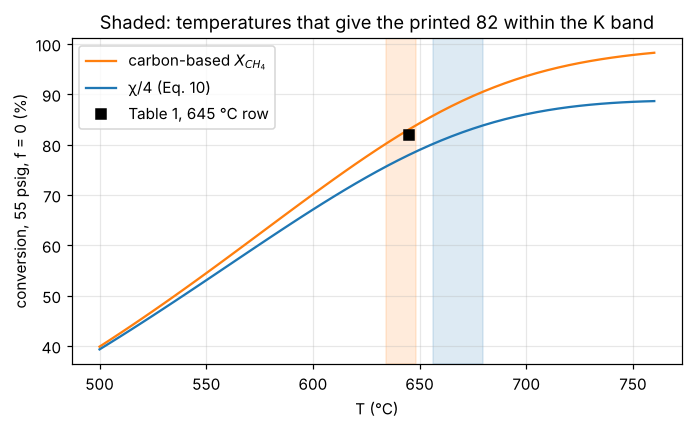

From the printed 645 °C composition alone, the carbon-based conversion is 0.8204 and χ/4 is 0.7704: the printed 82 is the carbon-based one. The re-solve agrees: $X_{CH_4}$ reaches 82 % at 641.1 °C and χ/4 at 667.3 °C. With the printed 82's rounding and the K band, $X_{CH_4}$ = 82 needs 634.1 to 648.6 °C, which holds 645 °C (3.6 °C from the nearer end), and χ/4 = 82 needs 656.4 to 679.9 °C, 11.4 °C above it. Table 1's 645 °C matches only the carbon-based conversion; matching the defined χ/4 of the SERP run's 82 would take 656 °C or more, not ~650 °C. Both readings of Table 1 (the carbon-based conversion, and the 50 psig numbers in the row labelled 55 psig) are inferences from the printed cells.

In [17]:
T_FIG = np.linspace(500.0, 760.0, 53)
br = Branch()
TC = np.array([[s.X, s.chi4] for s in (br.solve(C0.case(P_item="t1_645_P_psig", T_C=T))
                                         for T in T_FIG)]) * 100
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(T_FIG, TC[:, 0], "C1", label="carbon-based $X_{CH_4}$")
ax.plot(T_FIG, TC[:, 1], "C0", label="χ/4 (Eq. 10)")
for key, col in (("X", "C1"), ("chi4", "C0")):
    ax.axvspan(*M[f"_r3_{key}_interval"], color=col, alpha=0.15)
ax.plot([C0.num("t1_645_T_C")], [C0.num("t1_645_conv_pct")], "ks", label="Table 1, 645 °C row")
ax.set(xlabel="T (°C)", ylabel="conversion, 55 psig, f = 0 (%)",
       title="Shaded: temperatures that give the printed 82 within the K band")
ax.legend()
fig.tight_layout()
plt.show()
xi, ci = M["_r3_X_interval"], M["_r3_chi4_interval"]
say("From the printed 645 °C composition alone, the carbon-based conversion is "
    "<<px:.4f>> and χ/4 is <<pc:.4f>>: the printed 82 is the carbon-based one. The re-solve "
    "agrees: $X_{CH_4}$ reaches 82 % at <<tx:.1f>> °C and χ/4 at <<tc:.1f>> °C. With the "
    "printed 82's rounding and the K band, $X_{CH_4}$ = 82 needs <<xa:.1f>> to <<xb:.1f>> °C, "
    "which holds 645 °C (<<mx:.1f>> °C from the nearer end), and χ/4 = 82 needs <<ca:.1f>> "
    "to <<cb:.1f>> °C, <<mc:.1f>> °C above it. Table 1's 645 °C matches only the carbon-based "
    "conversion; matching the defined χ/4 of the SERP run's 82 would take <<ca:.0f>> °C or "
    "more, not ~650 °C. Both readings of Table 1 (the carbon-based conversion, and the 50 psig "
    "numbers in the row labelled 55 psig) are inferences from the printed cells.",
    px=M["r3_printed_Xcarbon"], pc=M["r3_printed_chi4"], tx=M["r3_Tstar_X"],
    tc=M["r3_Tstar_chi4"], xa=xi[0], xb=xi[1], ca=ci[0], cb=ci[1],
    mx=M["r3_645_in_table1_interval__margin"], mc=M["r3_645_in_other_interval__margin"])

### R4: the pressure of Table 1's 450 °C row, and R5: its 645 °C row

In [18]:
say("Moving the p. 251 numbers (50 psig) by the model's change from 50 to 55 psig "
    "(H2 <<sh:+.2f>>, CH4 <<sm:+.2f>>, CO + CO2 <<so:+.2f>>, conversion <<sc:+.2f>> points) "
    "makes <<n55:d>> of 4 Table 1 cells round to the printed 53, 34, 13 and 28; unmoved, "
    "<<n50:d>> of 4 do. Both counts hold with the p. 251 rounding and the shift's spread over "
    "the K band accounted for (smallest room <<m55:.2f>> and <<m50:.2f>> points). The row "
    "labelled 55 psig carries the 50 psig numbers. A direct re-solve at 55 psig cannot decide "
    "this alone: <<d0:d>> of 4 cells round at the centre K, but up to <<dm:d>> of 4 inside the "
    "band.\n\n"
    "The 645 °C row (55 psig): dry H2 <<h:.2f>>, CH4 <<m:.2f>>, CO + CO2 <<o:.2f>> % and "
    "$X_{CH_4}$ <<x:.2f>> % against 75.5, 4.4, 20.1 and 82; <<n5:d>> of 4 cells are consistent "
    "under the assumed ±<<b:.0f>> % band (smallest overlap <<m5:.2f>> points), <<r5:d>> of 4 round "
    "at the centre K, and <<n5b:d>> of 4 are consistent at ±<<bn:.0f>> % (smallest overlap "
    "<<m5b:.3f>> points).",
    sh=M["r4_shift_H2"], sm=M["r4_shift_CH4"], so=M["r4_shift_COx"], sc=M["r4_shift_conv"],
    n55=M["r4_n_p55"], n50=M["r4_n_p50"], m55=M["r4_n_p55__margin"], m50=M["r4_n_p50__margin"],
    d0=M["r4_direct_n55_centre"], dm=M["r4_direct_n55_band_max"], h=M["r5_H2"], m=M["r5_CH4"],
    o=M["r5_COx"], x=M["r5_X"], n5=M["r5_n_consistent"], m5=M["r5_n_consistent__margin"],
    r5=M["r5_n_round"], b=100 * C0.band, bn=100 * C0.band_narrow,
    n5b=M["r5_n_consistent_band5"], m5b=M["r5_n_consistent_band5__margin"])

Moving the p. 251 numbers (50 psig) by the model's change from 50 to 55 psig (H2 -0.68, CH4 +0.86, CO + CO2 -0.17, conversion -0.77 points) makes 1 of 4 Table 1 cells round to the printed 53, 34, 13 and 28; unmoved, 4 of 4 do. Both counts hold with the p. 251 rounding and the shift's spread over the K band accounted for (smallest room 0.10 and 0.20 points). The row labelled 55 psig carries the 50 psig numbers. A direct re-solve at 55 psig cannot decide this alone: 1 of 4 cells round at the centre K, but up to 4 of 4 inside the band.

The 645 °C row (55 psig): dry H2 75.71, CH4 4.13, CO + CO2 20.16 % and $X_{CH_4}$ 83.00 % against 75.5, 4.4, 20.1 and 82; 4 of 4 cells are consistent under the assumed ±10 % band (smallest overlap 0.09 points), 0 of 4 round at the centre K, and 3 of 4 are consistent at ±5 % (smallest overlap 0.020 points).

### R6 and R7: what the printed experiment and sorbent numbers allow

The SERP run, quoted from p. 255: "The conversion is 82% when the net H2 product is 0.8
mol/kg and the H2 product purity is 96% (balance CH4 + trace amounts of CO and CO2)." The
product is a cumulative average of a run whose CH4 fed, void volume and step time are not
printed, so no equilibrium verdict is possible; only the arithmetic of the printed numbers
is.

The sorbent sentence, p. 253: "fractional coverage of CO2 approaches unity when
$p_{CO_2}$ ≥ 0.3", with "[b = 39.9 atm⁻¹]" from the Fig. 6 fit at 400 °C, dry.

In [19]:
say("If all CO2 is held and all unconverted CH4 leaves with the product, conversion 82 % "
    "gives a dry H2 fraction of <<a:.4f>>, <<g:.2f>> points short of the printed 96 %; 96 % "
    "would need a conversion of <<x:.4f>>. Counting the printed pressurisation H2 into the "
    "product gives <<b:.4f>> (<<gb:.2f>> points short). The gap is the size of the unprinted "
    "CH4 hold-up and averaging; no verdict.\n\n"
    "The Langmuir form with the printed $b$ gives coverages <<t3:.3f>> at 0.3 atm and "
    "<<t7:.3f>> at 0.7 atm (ratio <<r:.3f>>), which supports the sentence at its own "
    "condition, 400 °C and dry CO2/N2. Nothing on this page uses $b$ at 450 °C in steam.",
    a=M["r6_yH2_closure"], g=M["r6_gap_pts"], x=M["r6_X_for_purity"],
    b=M["r6_yH2_closure_press"], gb=M["r6_gap_press_pts"], t3=M["r7_theta_lo"],
    t7=M["r7_theta_hi"], r=M["r7_theta_ratio"])

If all CO2 is held and all unconverted CH4 leaves with the product, conversion 82 % gives a dry H2 fraction of 0.9480, 1.20 points short of the printed 96 %; 96 % would need a conversion of 0.8571. Counting the printed pressurisation H2 into the product gives 0.9540 (0.60 points short). The gap is the size of the unprinted CH4 hold-up and averaging; no verdict.

The Langmuir form with the printed $b$ gives coverages 0.923 at 0.3 atm and 0.965 at 0.7 atm (ratio 0.956), which supports the sentence at its own condition, 400 °C and dry CO2/N2. Nothing on this page uses $b$ at 450 °C in steam.

## Validation

In [20]:
say("- **Two routes.** Route B (gas amounts, element balances, Eqs. 3 and 4, flat start) "
    "against route A (extents, Eqs. 8 and 9) at <<n:d>> states on sweeps in $1-f$ (1e-6 to 1) "
    "and $T$ (450 to 900 °C, at $f = 0$ and $1-f$ = 1e-3): largest relative gap in any mole "
    "fraction below 1e-10 (here <<g:.1e>>). The routes share only the K functions and the "
    "pressure.\n"
    "- **Identities.** Route A's element balances close to round-off (largest <<b:.1e>> per "
    "mole of feed); Eq. (5) and the corrected Eq. (6) hold at every state (largest relative "
    "gaps <<e5:.1e>> and <<e6:.1e>>). The printed Eq. (6) is off by the factor "
    "$\\sqrt{y_{H_2O}/y_{H_2}}$ = <<r6:.4f>> at the base state (an identity: the relative gap is below 1e-12, here <<r6g:.1e>>).\n"
    "- **Limits.** As $1-f \\to 0$ the local slope $d\\ln y_{CH_4,dry}/d\\ln(1-f)$ is "
    "<<s2:.4f>>, <<s4:.4f>> and <<s6:.4f>> at 1e-2, 1e-4 and 1e-6, approaching 1; χ/4 minus "
    "$X_{CH_4}$ falls to <<d6:.1e>> points at 1e-6 ($\\delta \\to \\beta$). At $f = 0$ and "
    "$P$ = 1e-4 atm the conversion is <<xp:.6f>> (the low-pressure limit is 1).\n"
    "- **Solver.** The analytic Jacobian against central differences: largest relative "
    "mismatch <<j:.1e>>. Newton step and backward-error tolerances 1e-8 against 1e-12 move $X_{CH_4}$ and the dry CH4 "
    "by at most <<te:.1e>> relative. Every threshold is the single root `find_roots` "
    "reports on its whole range.",
    n=len(OM_SWEEP) + 2 * len(T_SWEEP), g=M["v1_route_gap"], b=M["v1_element_balance"],
    e5=M["v3_eq5_gap"], e6=M["v3_eq6_corrected_gap"], r6=M["v3_eq6_printed_ratio"],
    r6g=M["v3_eq6_ratio_vs_sqrt"], s2=M["v2_slope_1e-02"], s4=M["v2_slope_1e-04"],
    s6=M["v2_slope_1e-06"], d6=M["v2_chi4_minus_X_1e-06"], xp=M["v2_X_P_low"],
    j=M["v4_jacobian"], te=M["v4_tol_effect"])

- **Two routes.** Route B (gas amounts, element balances, Eqs. 3 and 4, flat start) against route A (extents, Eqs. 8 and 9) at 45 states on sweeps in $1-f$ (1e-6 to 1) and $T$ (450 to 900 °C, at $f = 0$ and $1-f$ = 1e-3): largest relative gap in any mole fraction below 1e-10 (here 6.2e-15). The routes share only the K functions and the pressure.
- **Identities.** Route A's element balances close to round-off (largest 1.1e-16 per mole of feed); Eq. (5) and the corrected Eq. (6) hold at every state (largest relative gaps 1.1e-15 and 3.0e-15). The printed Eq. (6) is off by the factor $\sqrt{y_{H_2O}/y_{H_2}}$ = 2.2012 at the base state (an identity: the relative gap is below 1e-12, here 0.0e+00).
- **Limits.** As $1-f \to 0$ the local slope $d\ln y_{CH_4,dry}/d\ln(1-f)$ is 0.3082, 0.7947 and 0.9965 at 1e-2, 1e-4 and 1e-6, approaching 1; χ/4 minus $X_{CH_4}$ falls to -3.2e-06 points at 1e-6 ($\delta \to \beta$). At $f = 0$ and $P$ = 1e-4 atm the conversion is 1.000000 (the low-pressure limit is 1).
- **Solver.** The analytic Jacobian against central differences: largest relative mismatch 7.9e-11. Newton step and backward-error tolerances 1e-8 against 1e-12 move $X_{CH_4}$ and the dry CH4 by at most 1.0e-15 relative. Every threshold is the single root `find_roots` reports on its whole range.

In [21]:
# Register every reported number with its kind.
RTOL = 1e-6        # algebra at round-off: three BLAS kernels agree far inside this
STRUCTURAL = {
    "r3_printed_Xcarbon": "arithmetic of printed numbers", "r3_printed_chi4": "arithmetic of printed numbers",
    "r6_yH2_closure": "closed form of a printed number", "r6_X_for_purity": "closed form of a printed number",
    "r6_yH2_closure_press": "closed form of printed numbers", "r6_gap_pts": "closed form of printed numbers",
    "r6_gap_press_pts": "closed form of printed numbers", "r7_theta_lo": "Langmuir closed form",
    "r7_theta_hi": "Langmuir closed form", "r7_theta_ratio": "Langmuir closed form",
    "r7_theta_y0": "Langmuir closed form",
    "v3_eq6_printed_ratio": "equals sqrt(y_H2O/y_H2) by algebra (v3_eq6_ratio_vs_sqrt)"}
BOUNDS = {"v1_route_gap": (None, 1e-10, "tolerance", "route A against route B, newton tol 1e-10 and 1e-12", False),
          "v1_element_balance": (None, 1e-14, "identity", "Eq. (7) is built from the extents", True),
          "v3_eq5_gap": (None, 1e-12, "identity", "Eq. (5) is Eq. (3) times Eq. (4)", True),
          "v3_eq6_corrected_gap": (None, 1e-12, "identity", "corrected Eq. (6) from (3) and (4)", True),
          "v3_eq6_ratio_vs_sqrt": (None, 1e-12, "identity", "printed over true Eq. (6)", True),
          "v2_X_P_low": (0.9999, 1.0, "theory", "X -> 1 as P -> 0 at f = 0", True),
          "v4_jacobian": (None, 1e-6, "tolerance", "central differences, cbrt(eps) step", False),
          "v4_tol_effect": (None, 1e-8, "tolerance", "newton tol and backward_tol 1e-8 against 1e-12", False)}
MARGINS = {"r1_n_consistent": 0.01, "r1_n_round": 1e-6, "r5_n_consistent": 0.01,
           "r5_n_round": 1e-3, "r5_n_consistent_band5": 0.005, "r4_n_p55": 0.05, "r4_n_p50": 0.05, "r2_cox_holds": 0.1,
           "r2_h2_holds": 0.1, "r2_conv_verdict": 0.1, "r3_645_in_table1_interval": 0.5,
           "r3_645_in_other_interval": 0.5}
EXACT = {"r4_direct_n55_centre", "r4_direct_n55_band_max"}


def register(M):
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note, structural = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=structural, note=note)
        elif name in MARGINS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=MARGINS[name])
        elif name in EXACT:
            claims.exact(name, v)
        elif name in STRUCTURAL:
            claims.value(name, v, rtol=RTOL, note="structural: " + STRUCTURAL[name])
            claims.metrics[name]["structural"] = True
        else:
            claims.value(name, v, rtol=RTOL)


register(M)

### The break table

Every non-structural number registered above has a row that moves it. Each row injects one
defect through `Cfg` (a printed entry mistyped, a reading of the paper, a unit, the K
functions, the band, the validation route or the solver) and reruns the parts of the
study it reaches. Only finite values are recorded; a part that raises is listed. The
control fails nothing. Structural, with no row: the arithmetic of printed numbers (R3's
printed conversions, R6, R7), the element balances, the Eq. (5) and (6) identities and
the printed Eq. (6) ratio, and the low-pressure limit.

In [22]:
def printed_row(item, new, parts):
    """A break row that mistypes one printed entry."""
    pn = dict(C0.pn)
    old, pn[item] = pn[item], new
    return f"printed {item} {old} -> {new}", replace(C0, pn=pn), parts


ALL = tuple(PARTS)
RES = ("r1", "r2", "r3", "r4", "r5")
DEFECTS = [
    printed_row("p251_P_psig", "55", ("r1", "r2", "r4", "v2", "v4")),
    ("pressure passed as the psig number in atm", replace(C0, p_unit="psig_as_atm"), RES + ("v2", "v4")),
    ("Table 1 conversion read as chi/4", replace(C0, t1_conv="chi4"), ("r3", "r4", "r5")),
    printed_row("alpha", "6.5", ALL),
    ("95 % H2 tested on the wet basis", replace(C0, h2_basis="wet"), ("r2",)),
    ("K_WGS replaced by 1/K_WGS", replace(C0, wgs_inverted=True), RES + ("v2", "v4")),
    ("K band 0 instead of 10 %", replace(C0, band=0.0), ("r1", "r2", "r3", "r5")),
    ("narrow K band 0 instead of 5 %", replace(C0, band_narrow=0.0), ("r5",)),
    printed_row("t1_450_H2_pct", "52", ("r4",)),
    printed_row("t1_450_conv_pct", "27", ("r4",)),
    printed_row("t1_645_conv_pct", "84", ("r3",)),
    printed_row("t1_645_CH4_pct", "5.4", ("r5",)),
    printed_row("t1_645_H2_pct", "75.7", ("r5",)),
    printed_row("p251_f0_H2_pct", "54.8", ("r1", "r4")),
    printed_row("p251_f0_CO_pct", "0.44", ("r1",)),
    printed_row("p251_claim_COx_ppm", "300", ("r2",)),
    printed_row("p251_claim_H2_pct", "93", ("r2",)),
    printed_row("p251_claim_conv_pct", "75", ("r2",)),
    printed_row("p251_claim_removed_pct", "99.99", ("r2",)),
    ("route B: one O per sorbed CO2", replace(C0, o_sorbed=1.0), ("v13",)),
    ("route A Jacobian with a wrong term", replace(C0, jac_slip=0.5), ("v4",)),
    ("tolerance ladder from tol 1e-1", replace(C0, tol_loose=1e-1), ("v4",)),
]
CONTROLS = [("control: clean rerun of every part", C0, ALL)]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], {}
for row, c_, parts in CONTROLS + DEFECTS:
    Mb = {}
    for part in parts:                # one part at a time, so a crash costs only its own claims
        try:
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                Mb.update(study(c_, (part,)))
        except (ValueError, RuntimeError, ZeroDivisionError, FloatingPointError) as e:
            CRASH[f"{row} [{part}]"] = f"{type(e).__name__}: {str(e)[:80]}"
    for name in claims.metrics:
        if claims.metrics[name].get("structural"):
            continue
        x_ = Mb.get(name, None)
        if x_ is None or (isinstance(x_, (float, np.floating)) and not np.isfinite(x_)):
            continue                  # only finite values are recorded
        BREAK.append((row, name, claims.breaks(row, name, x_)))

In [23]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<58} {'recorded':>8} {'failed':>7}")
for r_, cs in by_row.items():
    print(f"{r_[:58]:<58} {len(cs):8d} {sum(cs):7d}")
for r_, e_ in CRASH.items():
    print(f"crashed part: {r_}: {e_}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
_n_struct = sum(1 for k_ in claims.metrics if claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {_n_struct}; open: {', '.join(_open) or 'none'}")

injected defect                                            recorded  failed
control: clean rerun of every part                               55       0
printed p251_P_psig 50 -> 55                                     39      30
pressure passed as the psig number in atm                        50      44
Table 1 conversion read as chi/4                                 21       5
printed alpha 6 -> 6.5                                           55      44
95 % H2 tested on the wet basis                                   9       1
K_WGS replaced by 1/K_WGS                                        54      46
K band 0 instead of 10 %                                         38       5
narrow K band 0 instead of 5 %                                   11       1
printed t1_450_H2_pct 53 -> 52                                    8       4
printed t1_450_conv_pct 28 -> 27                                  8       4
printed t1_645_conv_pct 82 -> 84                                  4       2
printed t1_6

### The finding

In [24]:
say("**Re-solving Eqs. 7 to 10 reproduces the paper's equilibrium numbers when its unprinted "
    "K is allowed an assumed band, but three statements do not follow as worded.**\n\n"
    "1. The printed states are consistent under an assumed ±<<b:.0f>> % band in both K "
    "(chosen, not measured): <<n1:d>> of 5 cells of the $f = 0$ state of p. 251 and <<n5:d>> "
    "of 4 of Table 1's 645 °C row; at the centre K <<r1:d>> of 5 and <<r5:d>> of 4 round; at "
    "±<<bn:.0f>> % <<n5b:d>> of 4.\n"
    "2. Table 1's \"CH4 Conversion\" is the carbon-based conversion, not the χ/4 the text "
    "defines: 645 °C lies inside the interval that gives $X_{CH_4}$ = 82 and <<mc:.1f>> °C "
    "below the one that gives χ/4 = 82, under every K in the band. Table 1's 645 °C matches "
    "only the carbon-based conversion (an inference from the printed cells).\n"
    "3. The 450 °C row labelled 55 psig carries the 50 psig numbers (an inference from the "
    "printed cells): <<n50:d>> of 4 cells match the p. 251 (50 psig) values and <<n55:d>> of 4 "
    "match them moved to 55 psig.\n"
    "4. \"> 95%\" H2 and \"< 100 ppm\" carbon oxides need more removal than the stated 99.9 %: "
    "the dry carbon oxides are <<p:.0f>> ppm at 99.9 %, not \"< 100 ppm\" (at least <<r:.2f>> "
    "times the bound in the band; 100 ppm needs $1-f$ ≤ <<oc:.2e>>), and the dry H2 is "
    "<<h:.2f>> %, not \"> 95%\" (95 % needs $1-f$ ≤ <<oh:.2e>>). Both verdicts hold across the "
    "K band. Clause (a), \"> 80%\" at 450 °C, has no removal condition and holds: χ/4 reaches "
    "80 % at $1-f$ = <<ov:.3e>>. At exactly 99.9 % the conversion is <<v3>> within the band.\n\n"
    "Out of scope, not judged: the SERP column's dynamics, kinetics, sorbent capacity at "
    "450 °C and the cycle, none of which the paper prints (Figs. 4 and 5 are at 400 °C).",
    n1=M["r1_n_consistent"], n5=M["r5_n_consistent"], r1=M["r1_n_round"],
    r5=M["r5_n_round"], b=100 * C0.band, bn=100 * C0.band_narrow, n5b=M["r5_n_consistent_band5"],
    mc=M["r3_645_in_other_interval__margin"], n50=M["r4_n_p50"], n55=M["r4_n_p55"],
    p=M["r2_999_COx_ppm"], r=q[:, 1].min() / C0.num("p251_claim_COx_ppm"),
    oc=M["r2_om_star_COx_ppm"], h=M["r2_999_H2"], oh=M["r2_om_star_H2"],
    v3=M["r2_conv_verdict"], ov=M["r2_om_star_chi4"])

**Re-solving Eqs. 7 to 10 reproduces the paper's equilibrium numbers when its unprinted K is allowed an assumed band, but three statements do not follow as worded.**

1. The printed states are consistent under an assumed ±10 % band in both K (chosen, not measured): 5 of 5 cells of the $f = 0$ state of p. 251 and 4 of 4 of Table 1's 645 °C row; at the centre K 1 of 5 and 0 of 4 round; at ±5 % 3 of 4.
2. Table 1's "CH4 Conversion" is the carbon-based conversion, not the χ/4 the text defines: 645 °C lies inside the interval that gives $X_{CH_4}$ = 82 and 11.4 °C below the one that gives χ/4 = 82, under every K in the band. Table 1's 645 °C matches only the carbon-based conversion (an inference from the printed cells).
3. The 450 °C row labelled 55 psig carries the 50 psig numbers (an inference from the printed cells): 4 of 4 cells match the p. 251 (50 psig) values and 1 of 4 match them moved to 55 psig.
4. "> 95%" H2 and "< 100 ppm" carbon oxides need more removal than the stated 99.9 %: the dry carbon oxides are 257 ppm at 99.9 %, not "< 100 ppm" (at least 2.55 times the bound in the band; 100 ppm needs $1-f$ ≤ 3.74e-04), and the dry H2 is 94.13 %, not "> 95%" (95 % needs $1-f$ ≤ 7.32e-04). Both verdicts hold across the K band. Clause (a), "> 80%" at 450 °C, has no removal condition and holds: χ/4 reaches 80 % at $1-f$ = 1.012e-03. At exactly 99.9 % the conversion is undecided within the band.

Out of scope, not judged: the SERP column's dynamics, kinetics, sorbent capacity at 450 °C and the cycle, none of which the paper prints (Figs. 4 and 5 are at 400 °C).

## What pymrm adds

Nothing beyond the paper's physics: the page reproduces and checks the paper's own
algebra. pymrm contributes the solve and the checks. `pymrm.newton` solves the two log
unknowns of Eqs. (8) and (9), with warm starts along sweeps in $1-f$ and $T$, and the
five-unknown balance formulation of the validation route;
`pymrm.checks.find_roots` gives every threshold and temperature as the single root on
its physical range; `pymrm.checks.check_jacobian` checks the analytic Jacobian. There is
no discretisation, so none of pymrm's operators is used.

## Reuse

- `model.solve_extents(Case(T_C, P_atm, om, kfun, alpha))` returns the batch equilibrium
  with a fraction 1 - `om` of the CO2 removed, for any K(T) given as a function; `State`
  gives wet and dry fractions and both conversions. Pass `kfun` explicitly: the paper
  gives none, and every number here depends on that choice. `model.Branch` follows a
  branch with warm starts for sweeps and root scans.
- Quote "conversion" with its definition: χ/4 (H2 yield) and the carbon-based conversion
  differ by several points at $f = 0$ above 600 °C.
- This is an equilibrium bound, not a reactor model. A sorption-enhanced column needs
  reforming kinetics (`C2.1`), a CO2 isotherm at the reaction temperature in steam, a
  sorbent capacity at that temperature and a mass-transfer model, none of which this
  paper prints (its Figs. 4 and 5 are at 400 °C).
- Related pages: `C2.1` (the K(T) correlations used here, and the kinetics),
  `I1.2` and `I1.3` (neighbouring entries in section I), `D2.6`.

In [25]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for I1.9:
  r1_chi4                     = 28.08            value  rtol 1e-06
  r1_gap_chi4                 = 0.080152         value  rtol 1e-06
  r1_H2                       = 52.901           value  rtol 1e-06
  r1_gap_H2                   = 0.10142          value  rtol 1e-06
  r1_CH4                      = 33.787           value  rtol 1e-06
  r1_gap_CH4                  = -0.01303         value  rtol 1e-06
  r1_CO2                      = 12.967           value  rtol 1e-06
  r1_gap_CO2                  = 0.066572         value  rtol 1e-06
  r1_CO                       = 0.34504          value  rtol 1e-06
  r1_gap_CO                   = 0.0050426        value  rtol 1e-06
  r1_n_consistent             = 5                exact  exact, margin 0.0318
  r1_n_round                  = 1                exact  exact, margin 4.26e-05
  r1_X                        = 28.263           value  rtol 1e-06
  r2_999_H2                   = 94.129           value  rtol 1e-06
  r2_om_star_H2        